<p style="align: center;"><img src="https://static.tildacdn.com/tild6636-3531-4239-b465-376364646465/Deep_Learning_School.png" width="400"></p>

# Глубокое обучение. Часть 2
# Домашнее задание по теме "Механизм внимания"

Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [ ]:
from torch import nn
import torch

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
device

device(type='cuda')

In [ ]:
from datasets import Dataset

In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
!pip install openpyxl

In [ ]:
df = pd.read_excel("/content/data_problems_translated.xlsx")

In [ ]:
hf_dataset = Dataset.from_pandas(df)

In [ ]:
import torch
from torch.utils.data import Dataset
from transformers import AutoTokenizer

class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels) if labels is not None else None
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])

        # Токенизируем текст
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
            padding=False,  # Лучше делать динамический паддинг в DataLoader через DataCollator
            return_tensors=None  # Возвращаем обычные списки/числа, collator сам переведет в тензоры
        )

        item = {key: torch.tensor(val) for key, val in encoding.items()}

        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)

        return item

In [ ]:
unique_labels = sorted(df['topic'].unique())
label2id = {label: idx for idx, label in enumerate(unique_labels)}
df['label_id'] = df['topic'].map(label2id)

In [ ]:
def tokenize_function(examples):
    texts = [str(text) if text is not None else "" for text in examples["problem_text"]]
    return tokenizer(texts, truncation=True, max_length=256)

In [ ]:
num_cl = 7

In [ ]:
df = df.dropna(subset=['problem_text'])

In [ ]:
df.iloc[1892]

,1893
Unnamed: 0,1893
problem_text,There are 27 pupils in the class: each of the ...
topic,dirichlet
label_id,1


In [ ]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

checkpoint = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# Замените 'text_column' и 'target_column' на реальные имена ваших колонок в таблице
dataset = TextClassificationDataset(
    texts=df['problem_text'].values,
    labels = df['label_id'].values,
    tokenizer=tokenizer,
    max_length=256
)

# DataCollatorWithPadding автоматически дополнит паддингом батч до самой длинной строки в этом батче
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=data_collator
)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
from typing import Union

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from transformers import AutoModel

In [ ]:
### This is just an interface example. You may change it if you want.

class TransformerClassificationModel(nn.Module):
    def __init__(self, base_transformer_model: Union[str, nn.Module], num_classes: int, dropout_rate: float = 0.1):
        super().__init__()
        if isinstance(base_transformer_model, str):
            # ❗️ ПРИНУДИТЕЛЬНО включаем выдачу внимания прямо в конфиге при загрузке
            self.backbone = AutoModel.from_pretrained(
                base_transformer_model,
                output_attentions=True
            )
        else:
            self.backbone = base_transformer_model
            self.backbone.config.output_attentions = True

        # Получаем размер скрытого слоя backbone
        hidden_size = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids=None, attention_mask=None, token_type_ids=None, labels=None, **kwargs):
        transformer_kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask
        }
        if token_type_ids is not None:
            transformer_kwargs["token_type_ids"] = token_type_ids

        # Защита от возможных конфликтов дублирования аргументов
        kwargs.pop("output_attentions", None)
        transformer_kwargs.update(kwargs)

        outputs = self.backbone(**transformer_kwargs)

        # Берем вектор первого токена [CLS] / <s>
        cls_rep = outputs.last_hidden_state[:, 0, :]
        cls_rep = self.dropout(cls_rep)
        logits = self.classifier(cls_rep)

        loss = None
        if labels is not None:
            loss_fn = nn.CrossEntropyLoss()
            loss = loss_fn(logits, labels)

        return {
            "loss": loss,
            "logits": logits,
            "attentions": outputs.attentions  # ❗️ Теперь здесь гарантированно будет кортеж с картами
        }

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [ ]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.named_parameters():
      if param[0][:10]!="classifier":
        param[1].requires_grad = False
    return model


### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [ ]:
import copy
from tqdm.auto import tqdm
import torch
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

def train_transformer(
    transformer_model: TransformerClassificationModel,
    train_loader: DataLoader,
    val_loader: DataLoader = None,
    freeze_backbone: bool = True,
    epochs: int = 3,
    lr: float = 1e-5,
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
) -> TransformerClassificationModel:
    """
    Дообучает TransformerClassificationModel с возможностью заморозки backbone.
    """
    # Создаем глубокую копию, чтобы не менять исходный объект
    finetuned_model = copy.deepcopy(transformer_model)

    if freeze_backbone:
        freeze_backbone_function(finetuned_model)
        # Если backbone заморожен, для классификатора можно задать learning rate повыше
        optimizer_lr = lr if lr > 1e-4 else 1e-3
    else:
        for param in finetuned_model.parameters():
            param.requires_grad = True
        optimizer_lr = lr

    finetuned_model.to(device)


    optimizer = AdamW(finetuned_model.parameters(), lr=optimizer_lr, weight_decay=0.01)

    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.1),
        num_training_steps=total_steps
    )

    for epoch in range(epochs):
        # --- Тренировочная эпоха ---
        finetuned_model.train()
        total_train_loss = 0.0
        correct_train = 0
        total_train_samples = 0

        train_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]")
        for batch in train_bar:
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = finetuned_model(**batch)
            loss = outputs["loss"]

            loss.backward()
            torch.nn.utils.clip_grad_norm_(finetuned_model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()

            total_train_loss += loss.item()
            preds = torch.argmax(outputs["logits"], dim=-1)
            correct_train += (preds == batch["labels"]).sum().item()
            total_train_samples += batch["labels"].size(0)

            train_bar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "acc": f"{correct_train / total_train_samples:.4f}"
            })

        # --- Валидация (если передан val_loader) ---
        if val_loader is not None:
            finetuned_model.eval()
            total_val_loss = 0.0
            correct_val = 0
            total_val_samples = 0

            with torch.no_grad():
                for batch in val_loader:
                    batch = {k: v.to(device) for k, v in batch.items()}
                    outputs = finetuned_model(**batch)

                    total_val_loss += outputs["loss"].item()
                    preds = torch.argmax(outputs["logits"], dim=-1)
                    correct_val += (preds == batch["labels"]).sum().item()
                    total_val_samples += batch["labels"].size(0)

            val_acc = correct_val / total_val_samples
            val_loss = total_val_loss / len(val_loader)
            print(f"Epoch {epoch + 1} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    return finetuned_model

In [ ]:
list(loader)[0]["labels"].shape

torch.Size([32])

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [ ]:
rubert_tiny_transformer_model = TransformerClassificationModel("roberta-base",7).to(device)
rubert_tiny_finetuned_with_freezed_backbone = train_transformer(rubert_tiny_transformer_model,loader, freeze_backbone=True)

rubert_tiny_transformer_model = TransformerClassificationModel("roberta-base",7).to(device)
rubert_tiny_full_finetuned = train_transformer(rubert_tiny_transformer_model,loader, freeze_backbone=False)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 3/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [ ]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

checkpoint = "tbs17/MathBert"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# Замените 'text_column' и 'target_column' на реальные имена ваших колонок в таблице
dataset = TextClassificationDataset(
    texts=df['problem_text'].values,
    labels = df['label_id'].values,
    tokenizer=tokenizer,
    max_length=256
)

# DataCollatorWithPadding автоматически дополнит паддингом батч до самой длинной строки в этом батче
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=data_collator
)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
rubert_tiny_transformer_model1 = TransformerClassificationModel("tbs17/MathBert",7).to(device)
rubert_tiny_finetuned_with_freezed_backbone1 = train_transformer(rubert_tiny_transformer_model,loader, freeze_backbone=True)

rubert_tiny_transformer_model1 = TransformerClassificationModel("tbs17/MathBert",7).to(device)
rubert_tiny_full_finetuned1 = train_transformer(rubert_tiny_transformer_model,loader, freeze_backbone=False)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  441MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 3/3 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

In [ ]:
t = dataset[0]
t = {k: v.unsqueeze(0).to(device) for k, v in t.items()}

In [ ]:
ru1 = TransformerClassificationModel("tbs17/MathBert",7).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
ru1(**t,output_attentions=True)

{'loss': tensor(1.5611, device='cuda:0', grad_fn=<NllLossBackward0>),
 'logits': tensor([[-0.7543, -0.1889,  0.9971, -0.2497,  0.1145,  0.5595, -0.3895]],
        device='cuda:0', grad_fn=<AddmmBackward0>),
 'attentions': (tensor([[[[6.6588e-02, 5.4190e-02, 6.8149e-02,  ..., 3.3978e-02,
             4.2411e-02, 1.1487e-01],
            [1.4050e-01, 1.9819e-02, 1.5278e-02,  ..., 8.0530e-02,
             4.2104e-02, 3.3245e-01],
            [1.5390e-01, 4.4929e-03, 1.8683e-02,  ..., 9.1185e-02,
             3.4890e-03, 2.7266e-02],
            ...,
            [1.6040e-02, 1.2993e-02, 1.6937e-01,  ..., 4.3844e-02,
             1.0582e-02, 2.3494e-01],
            [6.4496e-02, 4.1142e-03, 6.0770e-03,  ..., 6.5182e-02,
             1.1190e-02, 7.1202e-01],
            [3.3045e-02, 2.9786e-02, 8.0420e-03,  ..., 5.5568e-02,
             4.2252e-02, 3.0986e-01]],
  
           [[2.5390e-03, 3.1324e-02, 6.8404e-03,  ..., 3.2910e-02,
             6.0516e-02, 1.0634e-03],
            [2.6954e-02

### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [ ]:
from typing import List
import matplotlib.pyplot as plt
import seaborn as sns
import torch

In [ ]:
def draw_first_layer_attention_maps(attention_head_ids: List, text: str, model: TransformerClassificationModel,tokenizer):
    model.eval()
    model.to(device)
    inputs = tokenizer(text, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    first_layer_attentions = outputs["attentions"][0][0].cpu().numpy()

    num_heads = len(attention_head_ids)
    fig, axes = plt.subplots(1, num_heads, figsize=(6 * num_heads, 5), squeeze=False)

    for idx, head_id in enumerate(attention_head_ids):
        ax = axes[0, idx]
        head_attention = first_layer_attentions[head_id]

        sns.heatmap(
            head_attention,
            xticklabels=tokens,
            yticklabels=tokens,
            cmap="viridis",
            square=True,
            cbar=True,
            ax=ax
        )

        ax.set_title(f"Layer 1 | Head {head_id}")
        ax.set_xticklabels(tokens, rotation=90, fontsize=9)
        ax.set_yticklabels(tokens, rotation=0, fontsize=9)

    plt.tight_layout()
    plt.show()

### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

In [ ]:
checkpoint = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
checkpoint1 = "tbs17/MathBert"
tokenizer_mat = AutoTokenizer.from_pretrained(checkpoint)

In [ ]:
num_classes=7

In [ ]:
toke = [tokenizer,tokenizer_mat]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



==================== Модель: rubert-tiny2 (ДО ДООБУЧЕНИЯ) ====================

Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5....


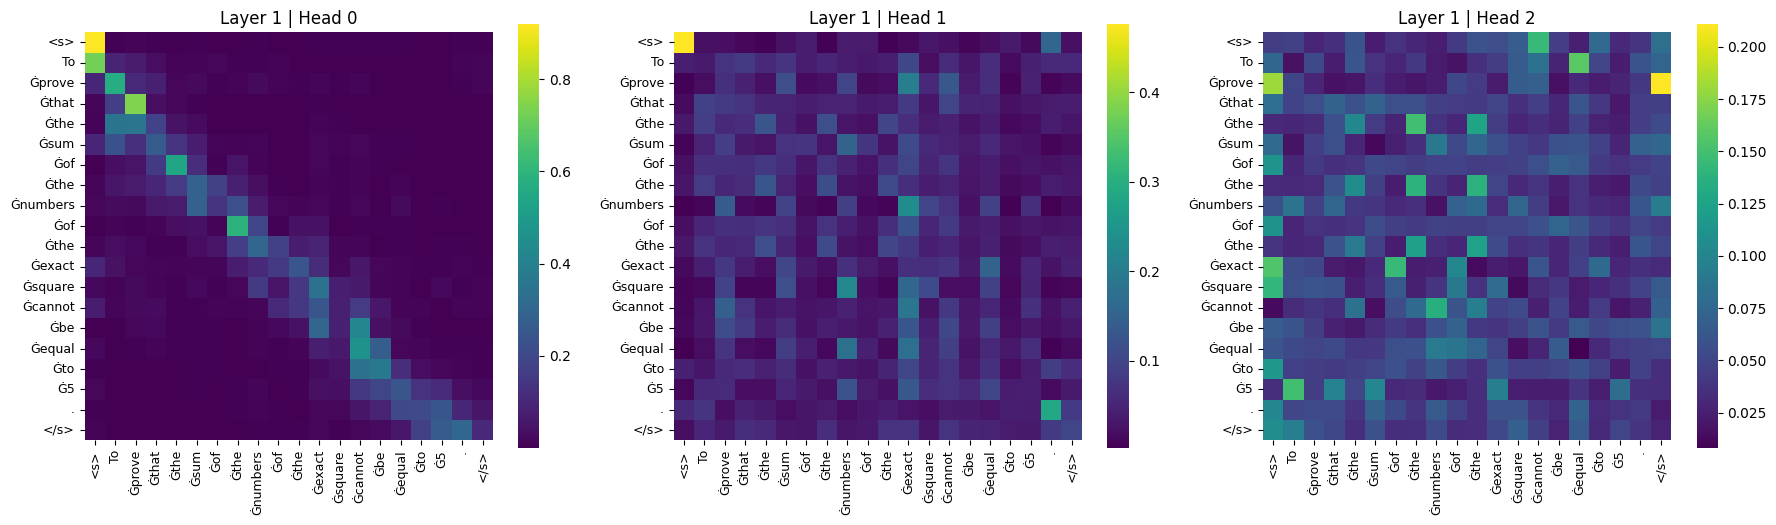


Текст: ( b) Will the statement of the previous challenge remain true if Petia and Wasa ...


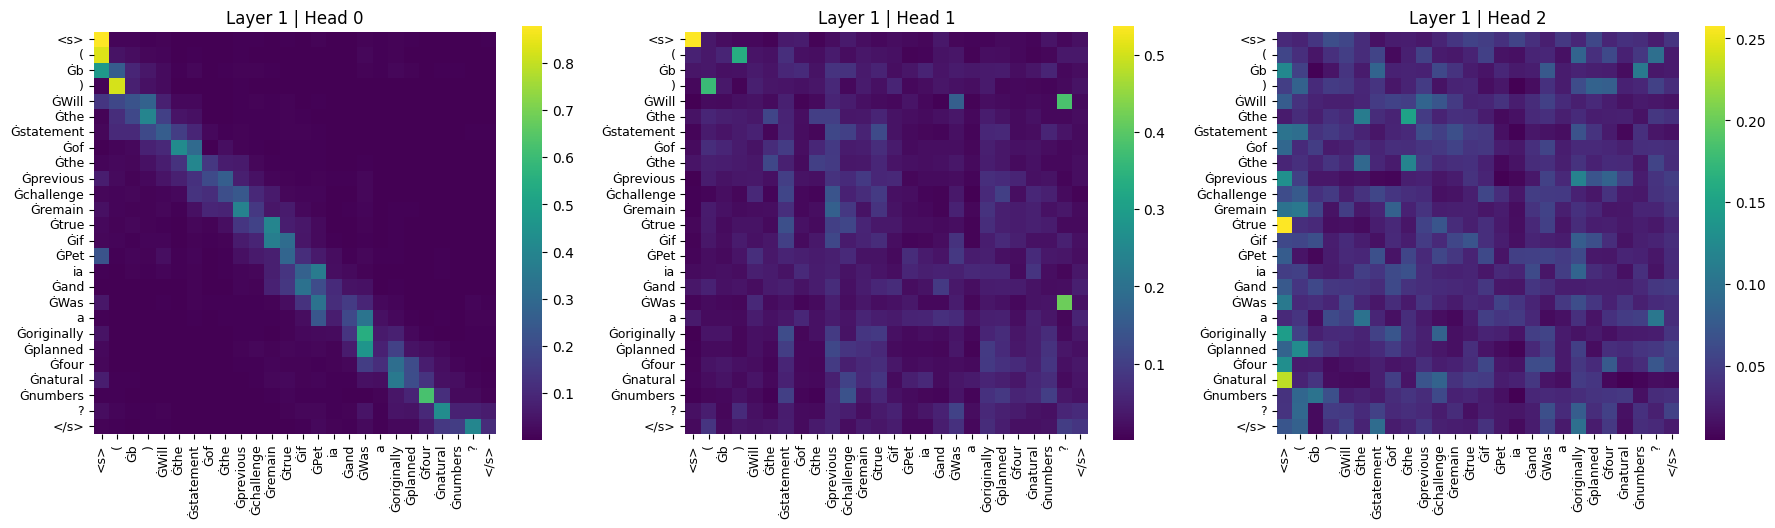

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



==================== Модель: MathBert (ДО ДООБУЧЕНИЯ) ====================

Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5....


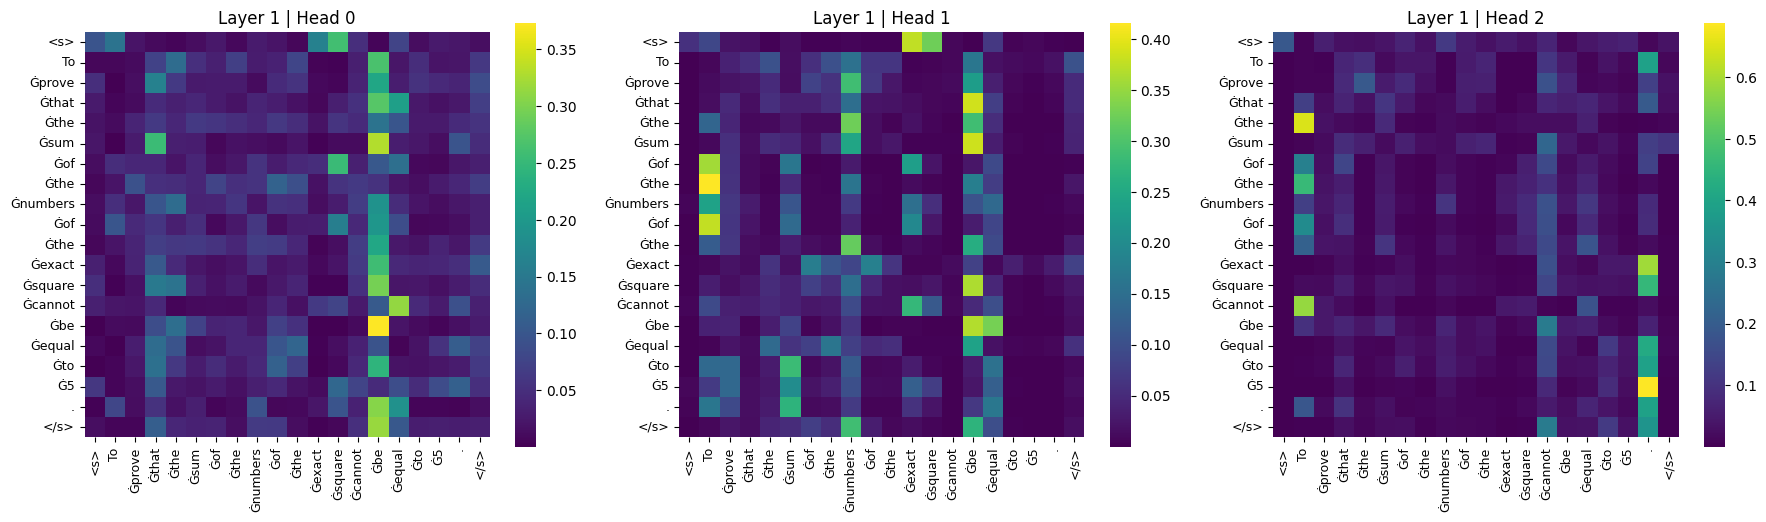


Текст: ( b) Will the statement of the previous challenge remain true if Petia and Wasa ...


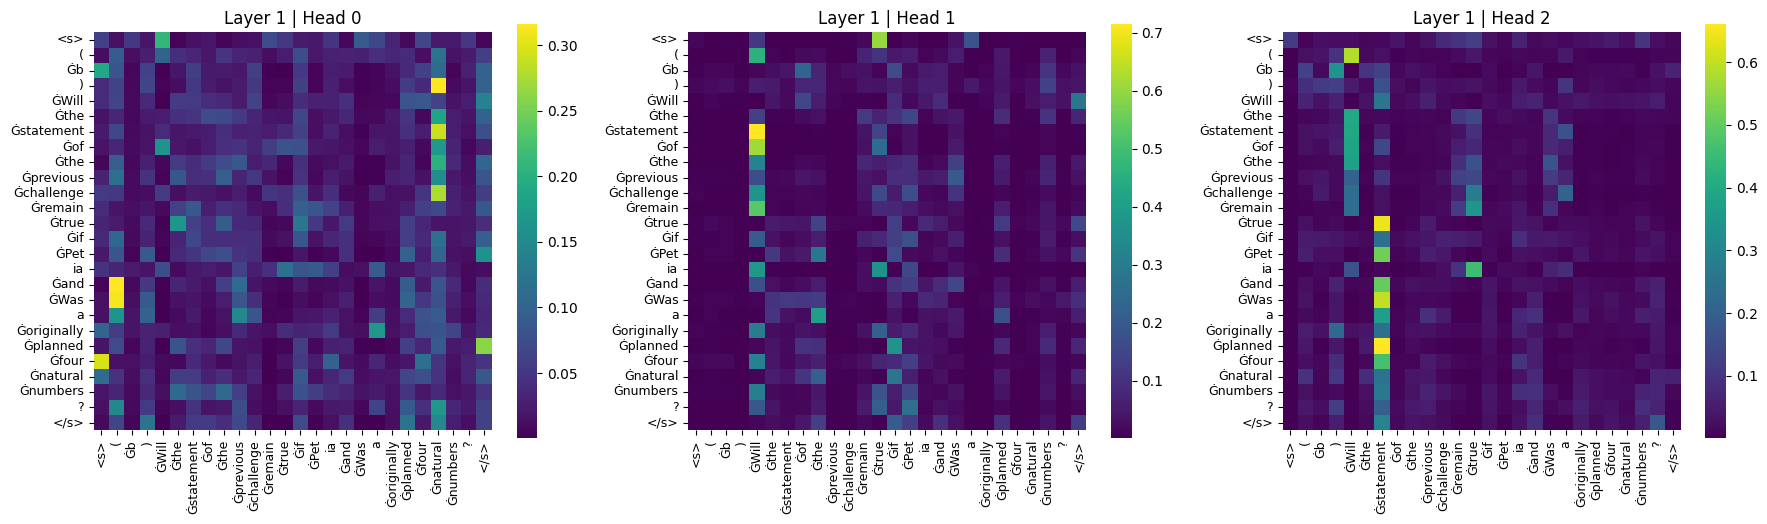

In [ ]:
sample_indices = [0, 1]
sample_texts = [df['problem_text'].iloc[i] for i in sample_indices]

# Список моделей для анализа
models_to_evaluate = [
    ("roberta-base", "rubert-tiny2"),
    ("tbs17/MathBert", "MathBert")
]

for i in range(len(models_to_evaluate)):
    model_name, display_name = models_to_evaluate[i]
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    raw_model = TransformerClassificationModel(model_name, num_classes=num_classes)

    print(f"\n==================== Модель: {display_name} (ДО ДООБУЧЕНИЯ) ====================")
    for text in sample_texts:
        # Берем первые несколько голов первого слоя (например, головы 0, 1, 2)
        print(f"\nТекст: {text[:80]}...")
        draw_first_layer_attention_maps(
            attention_head_ids=[0, 1, 2],
            text=text,
            model=raw_model,
            tokenizer = toke[i]
        )

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:01<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


==================== Модель: rubert-tiny2 (Full Finetuned) (ПОСЛЕ ДООБУЧЕНИЯ) ====================

Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5....


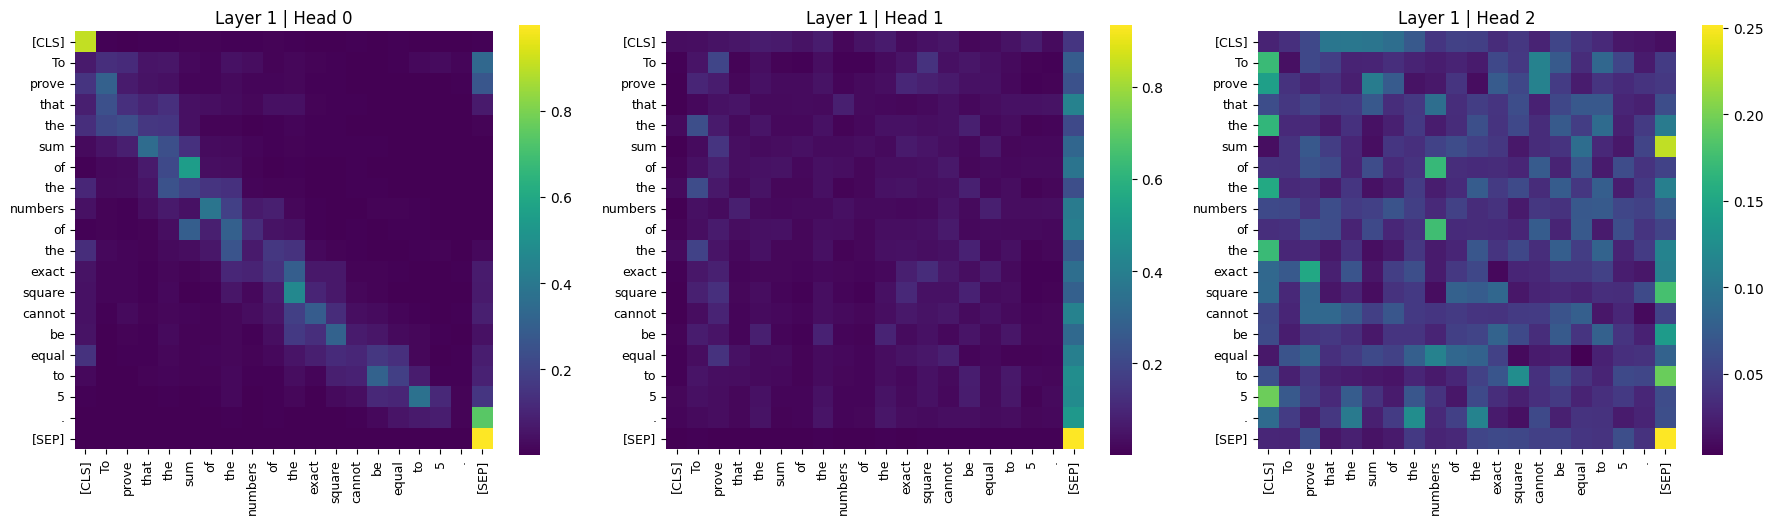


Текст: ( b) Will the statement of the previous challenge remain true if Petia and Wasa ...


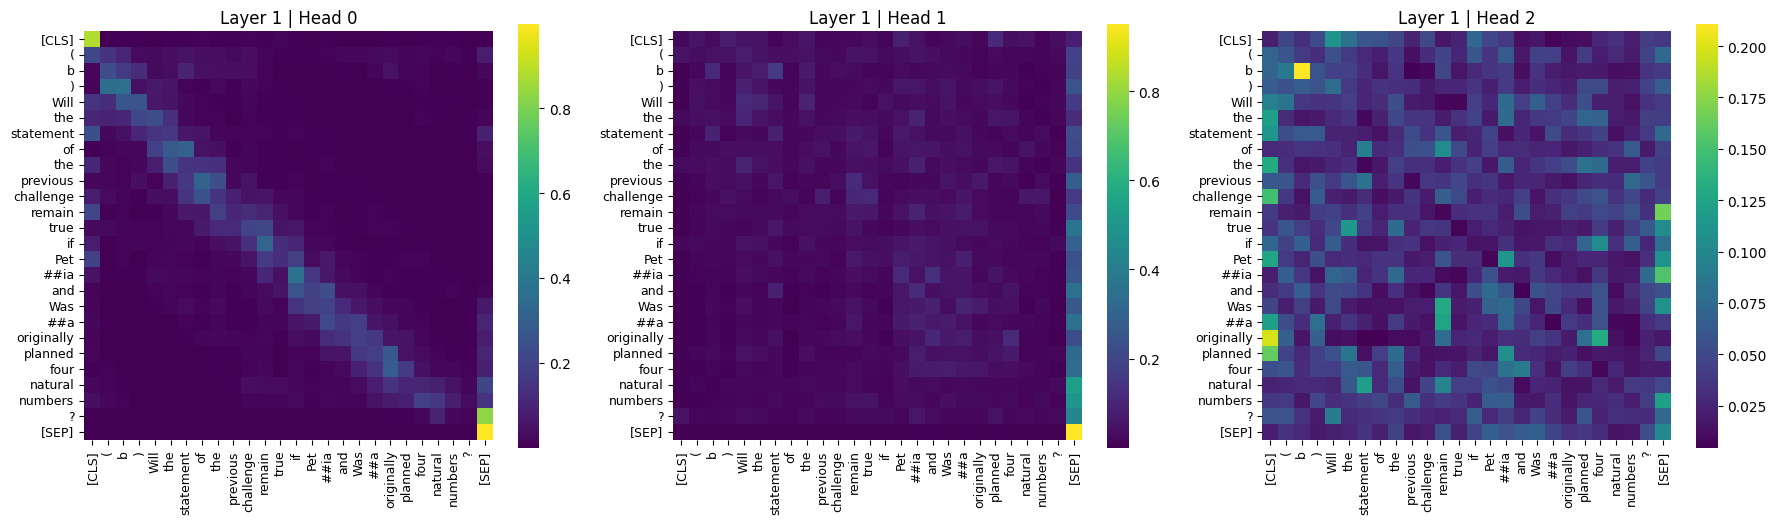


==================== Модель: MathBert (Full Finetuned) (ПОСЛЕ ДООБУЧЕНИЯ) ====================

Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5....


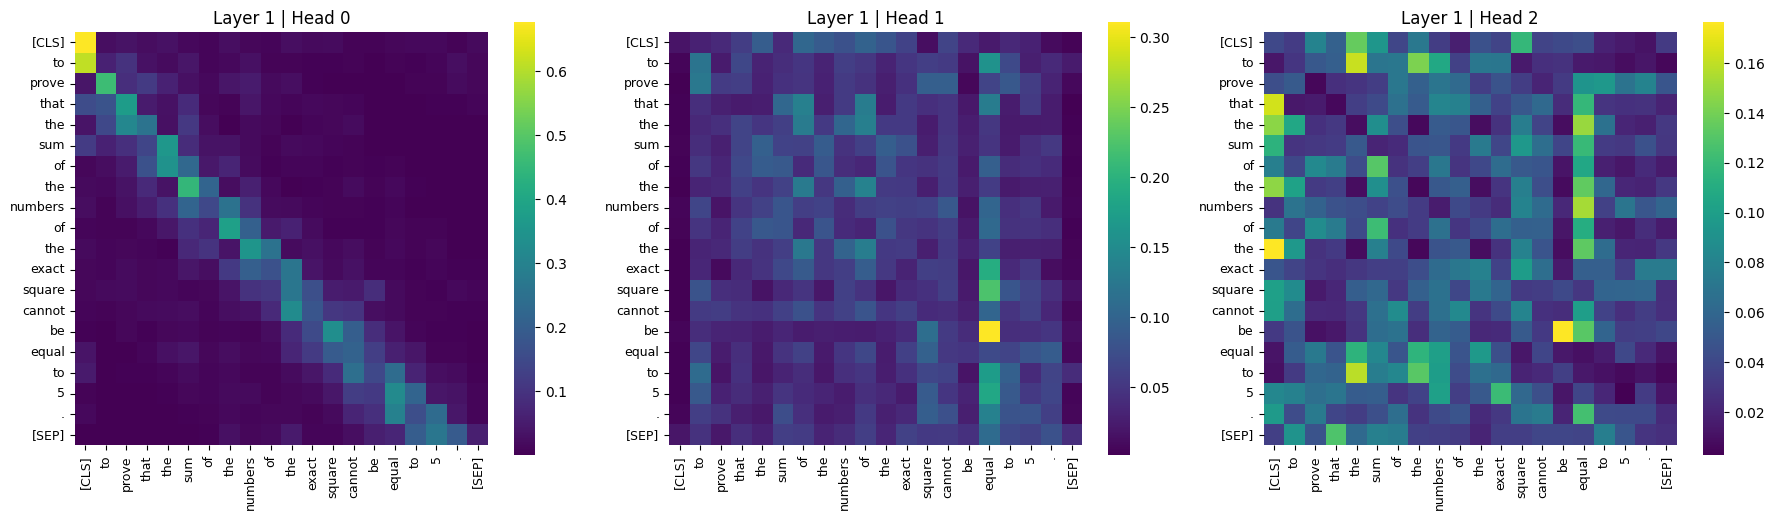


Текст: ( b) Will the statement of the previous challenge remain true if Petia and Wasa ...


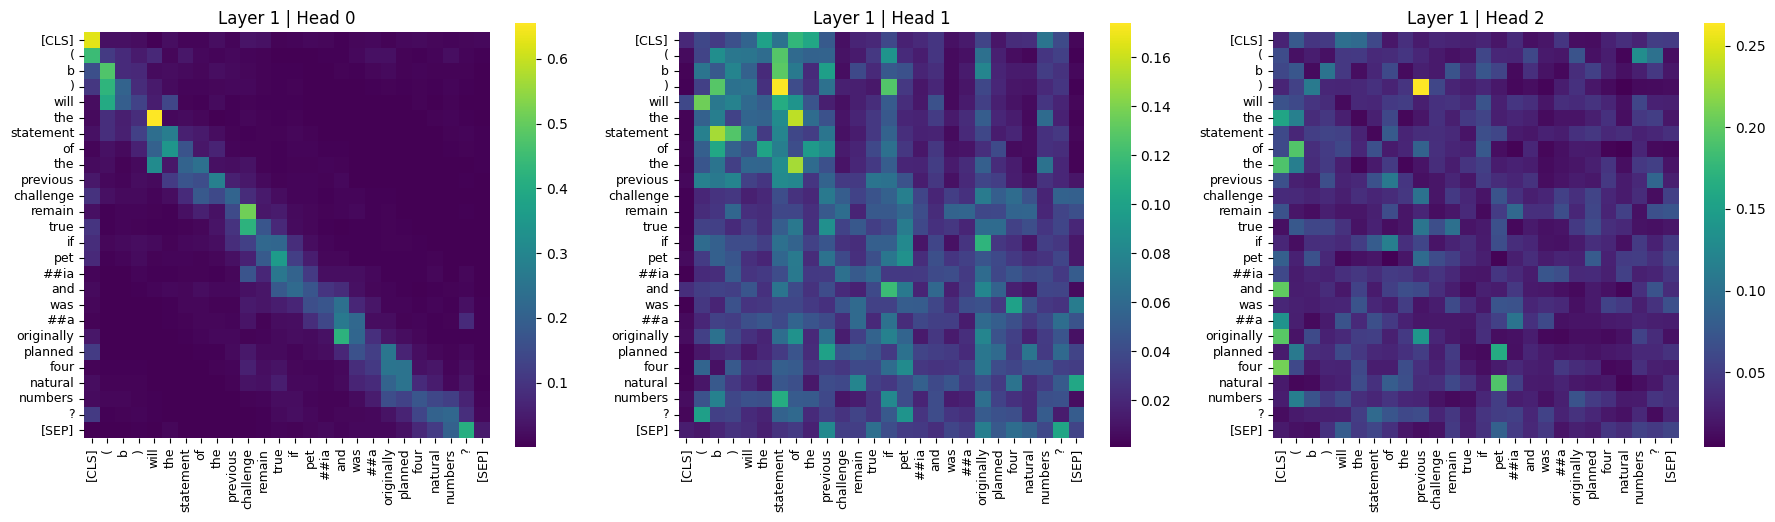

In [ ]:
# Словари дообученных моделей для сравнения
finetuned_models = [
    ("rubert-tiny2 (Full Finetuned)", rubert_tiny_full_finetuned, "cointegrated/rubert-tiny2"),
    ("MathBert (Full Finetuned)", rubert_tiny_full_finetuned1 , "tbs17/MathBert")
]

for display_name, trained_model, tokenizer_name in finetuned_models:
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)
    print(f"\n==================== Модель: {display_name} (ПОСЛЕ ДООБУЧЕНИЯ) ====================")
    for text in sample_texts:
        print(f"\nТекст: {text[:80]}...")
        draw_first_layer_attention_maps(
            attention_head_ids=[0, 1, 2],
            text=text,
            model=trained_model,
            tokenizer=tokenizer
        )